In [1]:
print("RP-FVIP data cleaning environment is ready!")

RP-FVIP data cleaning environment is ready!


In [3]:
demo_data.info()


<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   hhid                   5 non-null      int64
 1   province               5 non-null      str  
 2   household_size         5 non-null      int64
 3   education_years        5 non-null      int64
 4   has_financial_account  5 non-null      int64
 5   poverty_status         5 non-null      int64
dtypes: int64(5), str(1)
memory usage: 372.0 bytes


In [4]:
demo_data.describe(include="all")

,hhid,province,household_size,education_years,has_financial_account,poverty_status
count,5.000000,5,5.000000,5.000000,5.000000,5.000000
unique,NaN,5,NaN,NaN,NaN,NaN
top,NaN,Kigali,NaN,NaN,NaN,NaN
freq,NaN,1,NaN,NaN,NaN,NaN
mean,1003.000000,NaN,5.000000,7.600000,0.600000,0.600000
std,1.581139,NaN,1.581139,3.361547,0.547723,0.547723
min,1001.000000,NaN,3.000000,3.000000,0.000000,0.000000
25%,1002.000000,NaN,4.000000,6.000000,0.000000,0.000000
50%,1003.000000,NaN,5.000000,8.000000,1.000000,1.000000
75%,1004.000000,NaN,6.000000,9.000000,1.000000,1.000000


# RP-FVIP — EICV7 Data Cleaning & Validation

## Project
Rwanda Poverty & Financial Vulnerability Intelligence Platform (RP-FVIP)

## Purpose
This notebook defines and tests the data cleaning and validation
workflow for the EICV7 2023/24 data used in the project.

## Data Source
National Institute of Statistics of Rwanda (NISR) — EICV7 2023/24.

## Important Note
At this stage, the official EICV7 microdata are not yet available
in the project environment. Therefore, any demo data used for testing
will be clearly labeled as synthetic/demo data.

Synthetic/demo data must not be presented as official NISR estimates.

## Cleaning Workflow

1. File integrity check
2. Variable and data-type check
3. ID/key validation
4. Missing-value treatment
5. Value/range validation
6. Duplicate detection
7. Cross-file consistency
8. Survey-weight validation
9. Poverty-outcome validation
10. ML leakage audit
11. Creation of the clean analytical dataset
12. Data-quality report

In [5]:
demo_data.loc[2, "household_size"] = -3
demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status
0,1001,Kigali,4,12,1,0
1,1002,Southern,6,6,0,1
2,1003,Western,-3,9,1,0
3,1004,Eastern,5,3,0,1
4,1005,Northern,7,8,1,1


In [2]:
import pandas as pd

demo_data = pd.DataFrame({
    "hhid": [1001, 1002, 1003, 1004, 1005],
    "province": ["Kigali", "Southern", "Western", "Eastern", "Northern"],
    "household_size": [4, 6, 3, 5, 7],
    "education_years": [12, 6, 9, 3, 8],
    "has_financial_account": [1, 0, 1, 0, 1],
    "poverty_status": [0, 1, 0, 1, 1]
})

demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status
0,1001,Kigali,4,12,1,0
1,1002,Southern,6,6,0,1
2,1003,Western,3,9,1,0
3,1004,Eastern,5,3,0,1
4,1005,Northern,7,8,1,1


In [8]:
invalid_households = demo_data[demo_data["household_size"] <= 0]

invalid_households

,hhid,province,household_size,education_years,has_financial_account,poverty_status
2,1003,Western,-3,9,1,0


In [9]:
demo_data["invalid_household_size"] = demo_data["household_size"] <=0
demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4,12,1,0,False
1,1002,Southern,6,6,0,1,False
2,1003,Western,-3,9,1,0,True
3,1004,Eastern,5,3,0,1,False
4,1005,Northern,7,8,1,1,False


In [10]:
demo_data[demo_data["invalid_household_size"]]

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
2,1003,Western,-3,9,1,0,True


In [11]:
import numpy as np

demo_data.loc[demo_data["household_size"] <= 0, "household_size"] = np.nan

demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4.0,12,1,0,False
1,1002,Southern,6.0,6,0,1,False
2,1003,Western,NaN,9,1,0,True
3,1004,Eastern,5.0,3,0,1,False
4,1005,Northern,7.0,8,1,1,False


In [12]:
demo_data.isna().sum()

hhid                      0
province                  0
household_size            1
education_years           0
has_financial_account     0
poverty_status            0
invalid_household_size    0
dtype: int64

In [13]:
demo_data["has_financial_account"].value_counts()

has_financial_account
1    3
0    2
Name: count, dtype: int64

In [14]:
demo_data["poverty_status"].value_counts()

poverty_status
1    3
0    2
Name: count, dtype: int64

In [15]:
demo_data["hhid"].duplicated().sum()

np.int64(0)

In [16]:
demo_data.loc[4, "hhid"] = 1001

demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4.0,12,1,0,False
1,1002,Southern,6.0,6,0,1,False
2,1003,Western,NaN,9,1,0,True
3,1004,Eastern,5.0,3,0,1,False
4,1001,Northern,7.0,8,1,1,False


In [17]:
demo_data[demo_data["hhid"].duplicated(keep=False)]

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4.0,12,1,0,False
4,1001,Northern,7.0,8,1,1,False


In [18]:
demo_data = demo_data.drop_duplicates(subset="hhid", keep="first")

demo_data

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4.0,12,1,0,False
1,1002,Southern,6.0,6,0,1,False
2,1003,Western,NaN,9,1,0,True
3,1004,Eastern,5.0,3,0,1,False


In [19]:
print("Rows:", len(demo_data))
print("Unique households:", demo_data["hhid"].nunique())
print("Duplicate IDs:", demo_data["hhid"].duplicated().sum())
print("Missing values:")
print(demo_data.isna().sum())

Rows: 4
Unique households: 4
Duplicate IDs: 0
Missing values:
hhid                      0
province                  0
household_size            1
education_years           0
has_financial_account     0
poverty_status            0
invalid_household_size    0
dtype: int64


# EICV7 Cleaning & Validation Checklist

## 1. File Integrity
## 2. Household ID Validation
## 3. Person ID Validation
## 4. Missing-Value Validation
## 5. Value and Range Validation
## 6. Categorical-Code Validation
## 7. Cross-File Consistency
## 8. Survey Weight Validation
## 9. Poverty Outcome Validation
## 10. ML Leakage Audit

In [20]:
demo_data.to_csv("../data/demo/cleaned_demo_households.csv", index=False)

print("Cleaned demo dataset saved successfully.")

Cleaned demo dataset saved successfully.


In [21]:
import os

file_path = "../data/demo/cleaned_demo_households.csv"

print("File exists:", os.path.exists(file_path))

File exists: True


In [22]:
cleaned_demo = pd.read_csv(file_path)

cleaned_demo

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size
0,1001,Kigali,4.0,12,1,0,False
1,1002,Southern,6.0,6,0,1,False
2,1003,Western,NaN,9,1,0,True
3,1004,Eastern,5.0,3,0,1,False


In [23]:
cleaned_demo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hhid                    4 non-null      int64  
 1   province                4 non-null      str    
 2   household_size          3 non-null      float64
 3   education_years         4 non-null      int64  
 4   has_financial_account   4 non-null      int64  
 5   poverty_status          4 non-null      int64  
 6   invalid_household_size  4 non-null      bool   
dtypes: bool(1), float64(1), int64(4), str(1)
memory usage: 328.0 bytes


In [24]:
cleaned_demo["hhid"].isna().sum()

np.int64(0)

In [25]:
cleaned_demo["hhid"].duplicated().sum()

np.int64(0)

In [2]:
import pandas as pd

# Load the cleaned demo dataset
cleaned_demo = pd.read_csv("../data/demo/cleaned_demo_households.csv")

# Household ID validation
print("Missing hhid:", cleaned_demo["hhid"].isna().sum())
print("Duplicate hhid:", cleaned_demo["hhid"].duplicated().sum())
print("Unique hhid:", cleaned_demo["hhid"].nunique())
print("Total rows:", len(cleaned_demo))

Missing hhid: 0
Duplicate hhid: 0
Unique hhid: 4
Total rows: 4


In [3]:
# 2. Missing values, data types and basic range validation

print("=== DATA TYPES ===")
print(cleaned_demo.dtypes)

print("\n=== MISSING VALUES ===")
print(cleaned_demo.isna().sum())

print("\n=== RANGE CHECKS ===")
print("Household size <= 0:",
      (cleaned_demo["household_size"] <= 0).sum())

print("Education years < 0:",
      (cleaned_demo["education_years"] < 0).sum())

print("Education years > 30:",
      (cleaned_demo["education_years"] > 30).sum())

print("\n=== BINARY VARIABLES ===")
print("Financial account values:",
      cleaned_demo["has_financial_account"].unique())

print("Poverty status values:",
      cleaned_demo["poverty_status"].unique())

=== DATA TYPES ===
hhid                        int64
province                      str
household_size            float64
education_years             int64
has_financial_account       int64
poverty_status              int64
invalid_household_size       bool
dtype: object

=== MISSING VALUES ===
hhid                      0
province                  0
household_size            1
education_years           0
has_financial_account     0
poverty_status            0
invalid_household_size    0
dtype: int64

=== RANGE CHECKS ===
Household size <= 0: 0
Education years < 0: 0
Education years > 30: 0

=== BINARY VARIABLES ===
Financial account values: [1 0]
Poverty status values: [0 1]


In [4]:
# 3. Categorical validation + Poverty outcome + ML leakage audit

print("=== CATEGORICAL VARIABLES ===")

print("Province values:")
print(cleaned_demo["province"].unique())

print("\nFinancial account values:")
print(sorted(cleaned_demo["has_financial_account"].dropna().unique()))

print("\nPoverty status values:")
print(sorted(cleaned_demo["poverty_status"].dropna().unique()))


print("\n=== POVERTY OUTCOME CHECK ===")

print("Missing poverty status:",
      cleaned_demo["poverty_status"].isna().sum())

print("Poverty distribution:")
print(cleaned_demo["poverty_status"].value_counts())


print("\n=== ML LEAKAGE AUDIT ===")

target = "poverty_status"

potential_predictors = [
    "household_size",
    "education_years",
    "has_financial_account"
]

print("Target variable:", target)
print("Potential predictors:")

for variable in potential_predictors:
    print("-", variable)

print("\nLeakage variables NOT used as predictors:")
print("- consumption / expenditure variables")
print("- poverty score variables")
print("- variables directly used to construct the poverty target")

=== CATEGORICAL VARIABLES ===
Province values:
<StringArray>
['Kigali', 'Southern', 'Western', 'Eastern']
Length: 4, dtype: str

Financial account values:
[np.int64(0), np.int64(1)]

Poverty status values:
[np.int64(0), np.int64(1)]

=== POVERTY OUTCOME CHECK ===
Missing poverty status: 0
Poverty distribution:
poverty_status
0    2
1    2
Name: count, dtype: int64

=== ML LEAKAGE AUDIT ===
Target variable: poverty_status
Potential predictors:
- household_size
- education_years
- has_financial_account

Leakage variables NOT used as predictors:
- consumption / expenditure variables
- poverty score variables
- variables directly used to construct the poverty target


In [5]:
# 4. FINAL DATA QUALITY REPORT

print("=" * 50)
print("RP-FVIP — FINAL DEMO DATA QUALITY REPORT")
print("=" * 50)

print("\nDATASET")
print("Rows:", len(cleaned_demo))
print("Columns:", len(cleaned_demo.columns))

print("\nIDENTIFIERS")
print("Missing hhid:", cleaned_demo["hhid"].isna().sum())
print("Duplicate hhid:", cleaned_demo["hhid"].duplicated().sum())
print("Unique hhid:", cleaned_demo["hhid"].nunique())

print("\nMISSING VALUES")
print(cleaned_demo.isna().sum())

print("\nRANGE VALIDATION")
print("Invalid household size:",
      (cleaned_demo["household_size"] <= 0).sum())
print("Invalid education years:",
      ((cleaned_demo["education_years"] < 0) |
       (cleaned_demo["education_years"] > 30)).sum())

print("\nCATEGORICAL VALIDATION")
print("Financial account values:",
      sorted(cleaned_demo["has_financial_account"].dropna().unique()))
print("Poverty status values:",
      sorted(cleaned_demo["poverty_status"].dropna().unique()))

print("\nPOVERTY TARGET")
print("Missing poverty target:",
      cleaned_demo["poverty_status"].isna().sum())

print("\nML LEAKAGE")
print("Target:", "poverty_status")
print("Leakage variables excluded from predictors:",
      "consumption, expenditure and poverty-construction variables")

print("\nSTATUS: DEMO VALIDATION COMPLETED")
print("=" * 50)

RP-FVIP — FINAL DEMO DATA QUALITY REPORT

DATASET
Rows: 4
Columns: 7

IDENTIFIERS
Missing hhid: 0
Duplicate hhid: 0
Unique hhid: 4

MISSING VALUES
hhid                      0
province                  0
household_size            1
education_years           0
has_financial_account     0
poverty_status            0
invalid_household_size    0
dtype: int64

RANGE VALIDATION
Invalid household size: 0
Invalid education years: 0

CATEGORICAL VALIDATION
Financial account values: [np.int64(0), np.int64(1)]
Poverty status values: [np.int64(0), np.int64(1)]

POVERTY TARGET
Missing poverty target: 0

ML LEAKAGE
Target: poverty_status
Leakage variables excluded from predictors: consumption, expenditure and poverty-construction variables

STATUS: DEMO VALIDATION COMPLETED


In [6]:
# PHASE 4 — DATA DERIVATION

# 1. Household size group
def household_size_group(size):
    if pd.isna(size):
        return "Unknown"
    elif size <= 3:
        return "Small"
    elif size <= 6:
        return "Medium"
    else:
        return "Large"

cleaned_demo["household_size_group"] = (
    cleaned_demo["household_size"].apply(household_size_group)
)


# 2. Education level
def education_level(years):
    if years == 0:
        return "No formal education"
    elif years <= 6:
        return "Primary"
    elif years <= 12:
        return "Secondary"
    else:
        return "Higher"

cleaned_demo["education_level"] = (
    cleaned_demo["education_years"].apply(education_level)
)


# 3. Financial access
cleaned_demo["financial_access"] = (
    cleaned_demo["has_financial_account"]
    .map({0: "No access", 1: "Has access"})
)


# 4. Poverty group
cleaned_demo["poverty_group"] = (
    cleaned_demo["poverty_status"]
    .map({0: "Non-poor", 1: "Poor"})
)


# Display derived dataset
cleaned_demo

,hhid,province,household_size,education_years,has_financial_account,poverty_status,invalid_household_size,household_size_group,education_level,financial_access,poverty_group
0,1001,Kigali,4.0,12,1,0,False,Medium,Secondary,Has access,Non-poor
1,1002,Southern,6.0,6,0,1,False,Medium,Primary,No access,Poor
2,1003,Western,NaN,9,1,0,True,Unknown,Secondary,Has access,Non-poor
3,1004,Eastern,5.0,3,0,1,False,Medium,Primary,No access,Poor


In [7]:
print("=== DERIVED VARIABLES ===")

print("\nHousehold size groups:")
print(cleaned_demo["household_size_group"].value_counts())

print("\nEducation levels:")
print(cleaned_demo["education_level"].value_counts())

print("\nFinancial access:")
print(cleaned_demo["financial_access"].value_counts())

print("\nPoverty groups:")
print(cleaned_demo["poverty_group"].value_counts())

=== DERIVED VARIABLES ===

Household size groups:
household_size_group
Medium     3
Unknown    1
Name: count, dtype: int64

Education levels:
education_level
Secondary    2
Primary      2
Name: count, dtype: int64

Financial access:
financial_access
Has access    2
No access     2
Name: count, dtype: int64

Poverty groups:
poverty_group
Non-poor    2
Poor        2
Name: count, dtype: int64


In [8]:
# PHASE 5 — DATA ANALYSIS
# 1. Basic poverty analysis

poverty_rate = cleaned_demo["poverty_status"].mean() * 100

print("=== BASIC POVERTY ANALYSIS ===")
print("Total households:", len(cleaned_demo))
print("Poor households:",
      (cleaned_demo["poverty_status"] == 1).sum())
print("Non-poor households:",
      (cleaned_demo["poverty_status"] == 0).sum())
print("Poverty rate:", round(poverty_rate, 2), "%")

print("\nAverage household size:",
      round(cleaned_demo["household_size"].mean(), 2))

print("Average education years:",
      round(cleaned_demo["education_years"].mean(), 2))

=== BASIC POVERTY ANALYSIS ===
Total households: 4
Poor households: 2
Non-poor households: 2
Poverty rate: 50.0 %

Average household size: 5.0
Average education years: 7.5


In [9]:
# 2. Poverty by province

poverty_by_province = (
    cleaned_demo.groupby("province")["poverty_status"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="poverty_rate")
)

print("=== POVERTY BY PROVINCE ===")
print(poverty_by_province)

=== POVERTY BY PROVINCE ===
   province  poverty_rate
0   Eastern         100.0
1    Kigali           0.0
2  Southern         100.0
3   Western           0.0


In [10]:
# 3. Financial access and poverty

financial_poverty = (
    cleaned_demo.groupby("financial_access")["poverty_status"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="poverty_rate")
)

print("=== FINANCIAL ACCESS VS POVERTY ===")
print(financial_poverty)

=== FINANCIAL ACCESS VS POVERTY ===
  financial_access  poverty_rate
0       Has access           0.0
1        No access         100.0


In [11]:
# 4. Poverty by household-size group

size_poverty = (
    cleaned_demo.groupby("household_size_group")["poverty_status"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="poverty_rate")
)

print("=== POVERTY BY HOUSEHOLD SIZE ===")
print(size_poverty)

=== POVERTY BY HOUSEHOLD SIZE ===
  household_size_group  poverty_rate
0               Medium         66.67
1              Unknown          0.00


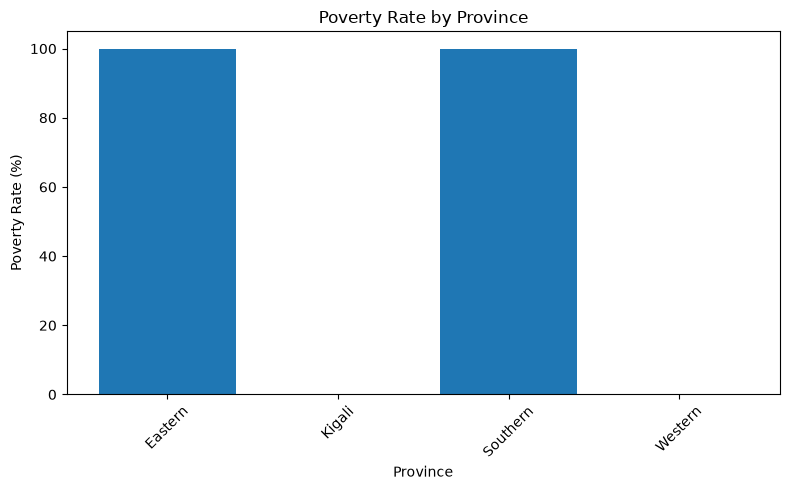

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    poverty_by_province["province"],
    poverty_by_province["poverty_rate"]
)

plt.title("Poverty Rate by Province")
plt.xlabel("Province")
plt.ylabel("Poverty Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

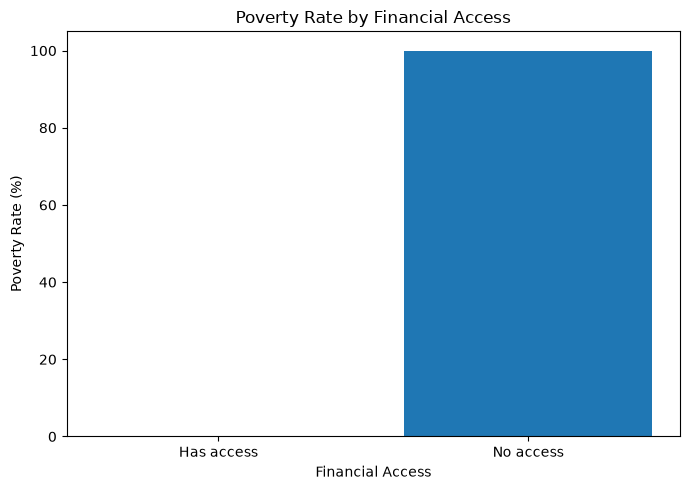

In [15]:
plt.figure(figsize=(7, 5))

plt.bar(
    financial_poverty["financial_access"],
    financial_poverty["poverty_rate"]
)

plt.title("Poverty Rate by Financial Access")
plt.xlabel("Financial Access")
plt.ylabel("Poverty Rate (%)")
plt.tight_layout()
plt.show()

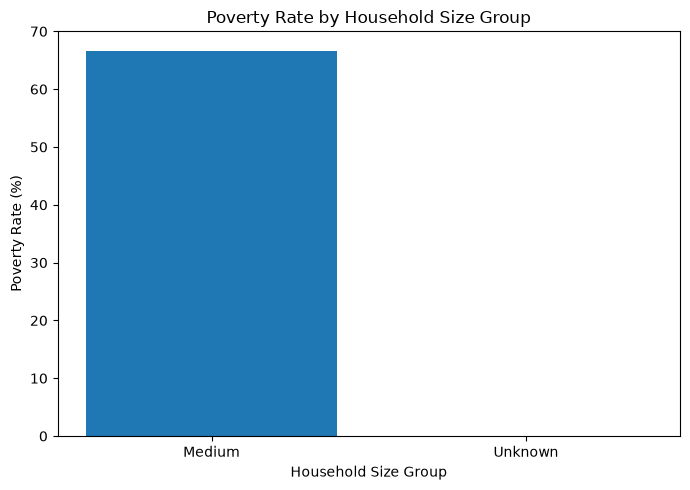

In [16]:
plt.figure(figsize=(7, 5))

plt.bar(
    size_poverty["household_size_group"],
    size_poverty["poverty_rate"]
)

plt.title("Poverty Rate by Household Size Group")
plt.xlabel("Household Size Group")
plt.ylabel("Poverty Rate (%)")
plt.tight_layout()
plt.show()

In [17]:
# PHASE 7 — ML / INTELLIGENCE
# 7A. Prepare ML dataset

from sklearn.model_selection import train_test_split

# Target
target = "poverty_status"

# Predictors
features = [
    "household_size",
    "education_years",
    "has_financial_account"
]

X = cleaned_demo[features].copy()
y = cleaned_demo[target].copy()

print("=== ML DATASET ===")
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values in X:")
print(X.isna().sum())

print("\nTarget distribution:")
print(y.value_counts())

=== ML DATASET ===
Features:
['household_size', 'education_years', 'has_financial_account']

Target:
poverty_status

X shape: (4, 3)
y shape: (4,)

Missing values in X:
household_size           1
education_years          0
has_financial_account    0
dtype: int64

Target distribution:
poverty_status
0    2
1    2
Name: count, dtype: int64


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Preprocessing + model
ml_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

print("ML pipeline created successfully.")
print(ml_pipeline)

ML pipeline created successfully.
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LogisticRegression())])


In [19]:
# 7C. Create synthetic data for ML pipeline testing

import numpy as np
import pandas as pd

np.random.seed(42)

n = 200

ml_demo = pd.DataFrame({
    "household_size": np.random.randint(1, 11, n),
    "education_years": np.random.randint(0, 16, n),
    "has_financial_account": np.random.randint(0, 2, n)
})

# Create a synthetic poverty outcome for pipeline testing
poverty_score = (
    0.25 * ml_demo["household_size"]
    - 0.20 * ml_demo["education_years"]
    - 1.00 * ml_demo["has_financial_account"]
    + np.random.normal(0, 1.5, n)
)

ml_demo["poverty_status"] = (poverty_score > 0.5).astype(int)

print("=== SYNTHETIC ML TEST DATA ===")
print("Rows:", len(ml_demo))
print("Columns:", len(ml_demo.columns))

print("\nTarget distribution:")
print(ml_demo["poverty_status"].value_counts())

print("\nFirst 5 rows:")
print(ml_demo.head())

=== SYNTHETIC ML TEST DATA ===
Rows: 200
Columns: 4

Target distribution:
poverty_status
0    148
1     52
Name: count, dtype: int64

First 5 rows:
   household_size  education_years  has_financial_account  poverty_status
0               7                5                      0               1
1               4               10                      0               0
2               8               14                      1               0
3               5               15                      1               0
4               7               15                      1               0


In [20]:
# 7D. Train-test split

X_ml = ml_demo[
    ["household_size", "education_years", "has_financial_account"]
]

y_ml = ml_demo["poverty_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X_ml,
    y_ml,
    test_size=0.20,
    random_state=42,
    stratify=y_ml
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 160
Testing rows: 40
Training target distribution:
poverty_status
0    118
1     42
Name: count, dtype: int64

Testing target distribution:
poverty_status
0    30
1    10
Name: count, dtype: int64


In [21]:
# 7E. Train the ML model

ml_pipeline.fit(X_train, y_train)

print("ML model trained successfully.")

ML model trained successfully.


In [22]:
# 7F. Evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_pred = ml_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=== MODEL EVALUATION ===")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

=== MODEL EVALUATION ===
Accuracy : 0.775
Precision: 1.0
Recall   : 0.1
F1 Score : 0.182

Confusion Matrix:
[[30  0]
 [ 9  1]]


In [23]:
# 7F — Random Forest model

from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train, y_train)

rf_pred = rf_pipeline.predict(X_test)

print("=== RANDOM FOREST EVALUATION ===")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall   :", round(recall_score(y_test, rf_pred), 3))
print("F1 Score :", round(f1_score(y_test, rf_pred), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

=== RANDOM FOREST EVALUATION ===
Accuracy : 0.675
Precision: 0.2
Recall   : 0.1
F1 Score : 0.133

Confusion Matrix:
[[26  4]
 [ 9  1]]


In [24]:
# 7G — Compare ML models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ]
})

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.775,1.0,0.1,0.182
1,Random Forest,0.675,0.2,0.1,0.133


In [25]:
# 7H — Feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_pipeline.named_steps["model"].feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("=== RANDOM FOREST FEATURE IMPORTANCE ===")
print(feature_importance)

=== RANDOM FOREST FEATURE IMPORTANCE ===
                 Feature  Importance
0        education_years    0.570198
1         household_size    0.255551
2  has_financial_account    0.174252


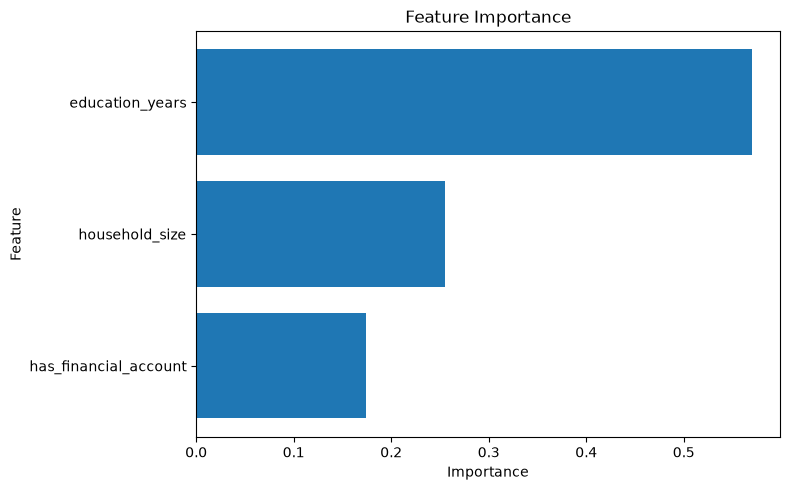

In [26]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [27]:
# 7I — Prepare data for SHAP

import shap

# Apply the same preprocessing used by the Random Forest
X_train_processed = rf_pipeline.named_steps["imputer"].transform(X_train)

print("SHAP data prepared successfully.")
print("Shape:", X_train_processed.shape)

SHAP data prepared successfully.
Shape: (160, 3)


In [28]:
# Create SHAP explainer

rf_model = rf_pipeline.named_steps["model"]

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_train_processed)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


Generating SHAP summary plot...


C:\Users\user\AppData\Local\Temp\ipykernel_13392\1863352197.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


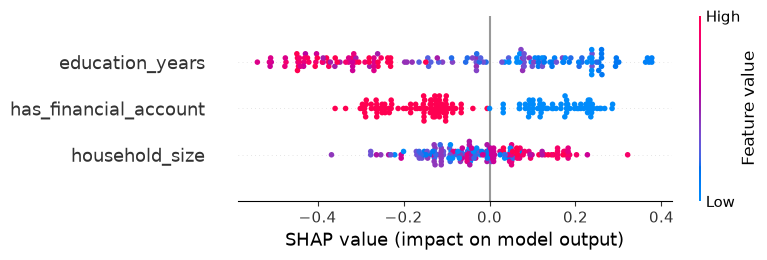

In [29]:
# 7J — SHAP Summary Plot

import numpy as np

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_class1 = shap_values[1]
else:
    if shap_values.ndim == 3:
        shap_class1 = shap_values[:, :, 1]
    else:
        shap_class1 = shap_values

# Create a DataFrame with the original feature names
X_train_shap = pd.DataFrame(
    X_train_processed,
    columns=X_train.columns
)

print("Generating SHAP summary plot...")

shap.summary_plot(
    shap_class1,
    X_train_shap,
    show=True
)

In [30]:
# PHASE 8 — FINAL ANALYTICAL DATASET

final_columns = [
    "hhid",
    "province",
    "household_size",
    "household_size_group",
    "education_years",
    "education_level",
    "has_financial_account",
    "financial_access",
    "poverty_status",
    "poverty_group"
]

analytical_demo = cleaned_demo[final_columns].copy()

print("=== FINAL ANALYTICAL DATASET ===")
print("Rows:", len(analytical_demo))
print("Columns:", len(analytical_demo.columns))

analytical_demo

=== FINAL ANALYTICAL DATASET ===
Rows: 4
Columns: 10


,hhid,province,household_size,household_size_group,education_years,education_level,has_financial_account,financial_access,poverty_status,poverty_group
0,1001,Kigali,4.0,Medium,12,Secondary,1,Has access,0,Non-poor
1,1002,Southern,6.0,Medium,6,Primary,0,No access,1,Poor
2,1003,Western,NaN,Unknown,9,Secondary,1,Has access,0,Non-poor
3,1004,Eastern,5.0,Medium,3,Primary,0,No access,1,Poor


In [31]:
# Final analytical dataset quality check

print("=== QUALITY CHECK ===")

print("Missing values:")
print(analytical_demo.isna().sum())

print("\nDuplicate households:",
      analytical_demo["hhid"].duplicated().sum())

print("\nData types:")
print(analytical_demo.dtypes)

=== QUALITY CHECK ===
Missing values:
hhid                     0
province                 0
household_size           1
household_size_group     0
education_years          0
education_level          0
has_financial_account    0
financial_access         0
poverty_status           0
poverty_group            0
dtype: int64

Duplicate households: 0

Data types:
hhid                       int64
province                     str
household_size           float64
household_size_group         str
education_years            int64
education_level              str
has_financial_account      int64
financial_access             str
poverty_status             int64
poverty_group                str
dtype: object


In [32]:
# Save final analytical dataset

analytical_demo.to_csv(
    "../data/demo/final_analytical_demo.csv",
    index=False
)

print("Final analytical demo dataset saved successfully.")

Final analytical demo dataset saved successfully.


In [33]:
# PHASE 9A — Create local RP-FVIP database

import sqlite3

# Create database
db_path = "../data/demo/rp_fvip_demo.db"

conn = sqlite3.connect(db_path)

# Save analytical dataset into database
analytical_demo.to_sql(
    "households",
    conn,
    if_exists="replace",
    index=False
)

print("RP-FVIP demo database created successfully.")
print("Database:", db_path)

RP-FVIP demo database created successfully.
Database: ../data/demo/rp_fvip_demo.db


In [34]:
# 9B — Test database connection

query = """
SELECT *
FROM households
LIMIT 5;
"""

db_test = pd.read_sql_query(query, conn)

print("=== DATABASE TEST ===")
print(db_test)

=== DATABASE TEST ===
   hhid  province  household_size household_size_group  education_years  \
0  1001    Kigali             4.0               Medium               12   
1  1002  Southern             6.0               Medium                6   
2  1003   Western             NaN              Unknown                9   
3  1004   Eastern             5.0               Medium                3   

  education_level  has_financial_account financial_access  poverty_status  \
0       Secondary                      1       Has access               0   
1         Primary                      0        No access               1   
2       Secondary                      1       Has access               0   
3         Primary                      0        No access               1   

  poverty_group  
0      Non-poor  
1          Poor  
2      Non-poor  
3          Poor  


In [35]:
# 9C — Poverty rate by province from database

query = """
SELECT
    province,
    COUNT(*) AS households,
    AVG(poverty_status) * 100 AS poverty_rate
FROM households
GROUP BY province
ORDER BY poverty_rate DESC;
"""

poverty_from_db = pd.read_sql_query(query, conn)

poverty_from_db

,province,households,poverty_rate
0,Southern,1,100.0
1,Eastern,1,100.0
2,Western,1,0.0
3,Kigali,1,0.0


In [36]:
# Close database connection

conn.close()

print("Database connection closed.")

Database connection closed.
